# Tarea 2 — Nuestro modelo de Machine Learning
## Predicción de secuencias sísmicas a partir del catálogo del USGS

**Integrantes:** Josefina Yantén y Daniel Faúndez

**Dataset:** `earthquakes_usgs.csv` — catálogo del U.S. Geological Survey

En la Tarea 1 analizamos este catálogo y propusimos, al final, un problema de Machine
Learning. Acá lo implementamos.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, classification_report, f1_score

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

df = pd.read_csv('earthquakes_usgs.csv', index_col=0)
df['time'] = pd.to_datetime(df['time'], format='mixed', utc=True)
df['year'] = df['time'].dt.year

print("Catálogo completo:", df.shape)

Catálogo completo: (310535, 13)


---
## 1. Definición del problema de predicción

### ¿Que variable intentaremos predecir? (target)

Utilizando el problema planteado en la tarea 1, lo que intentaremos responder es: dado un sismo de magnitud 6 o mayor que acaba de ocurrir, ¿aparecerá otro sismo igual o mayor en los próximos 30 días dentro de un radio de 200 km? O sea, si ese temblor fue un evento aislado o si es el inicio de una secuencia de sismos.

### ¿Que variables se utilizarán como entrada (features)?

Un detalle importante es que todas las features tienen que estar disponibles en el instante en que ocurre el sismo, si se usara información posterior al sismo sería como hacer trampa ya que en una situación real no se tendría información del futuro. Las features que usamos son las siguientes. 

- `mag` : la magnitud del sismo. 
- `depth` : la profundidad del hipocentro. 
- `lat` , `lon` : las coordenadas del epicentro.

- `nprev` : cuántos sismos M ≥ 4,5 ocurrieron en un radio de 200 km durante el año anterior. Esto ayuda a visualizar qué tan activa venía la zona.
- `magmax_prev` : la magnitud del mayor sismo de esa misma zona en ese mismo año. Sirve para distinguir una zona con mucho temblor chico de una que ya tuvo un evento grande.

Las dos últimas features no vienen en el catálogo, las construimos nosotros. Respecto de la propuesta original de la Tarea 1, cambiamos la región por las coordenadas directamente, que dicen lo mismo sin obligarnos a definir fronteras, y agregamos `magmax_prev`.

### ¿Se trata de un problema de clasificación o regresión?

El problema que trabajaremos en esta tarea se trata de uno de clasificación binaria, el target vale 1 si hubo un evento posterior que cumple las condiciones planteadas y 0 si no las cumple. Cada observación del dataset es un sismo M ≥ 6 del catálogo.

### ¿Por qué consideramos que los datos disponibles podrían contener información útil para realizar esta predicción?

Cconsideramos que contiene información útil rincipalmente porque el fenómeno es frecuente. En la Tarea 1 vimos que un 23 % de los sismos M ≥ 6 desde 1980 tuvo otro evento similar cerca en los 30 días siguientes, así que tenemos bastantes ejemplos de ambas clases que nos ayudaran a generar y trabajar con la predicción.

---
## 2. Construcción del dataset

El catálogo no trae la variable que queremos predecir, hay que armarla. Para cada sismo M ≥ 6 revisamos qué pasó después en su vecindad (radio de 200 km) y le ponemos la etiqueta que corresponde.

Hay cuatro decisiones que tomamos acá y que conviene dejar explícitas:

1. Usamos solo el período 1980–2025. Esto ya lo habíamos anticipado en la Tarea 1 como una dificultad: si en alguna época la red no registraba bien, un sismo quedaría etiquetado como "sin réplicas" cuando en realidad sí las tuvo, solo que nadie las anotó por falta de precisión en la instrumentación. Desde 1980 el catálogo es parejo y confiable para M ≥ 4,5, así que entrenamos con eventos posteriores a esa fecha para no generar problemas en el modelo.

2. Definimos secuencia como otro sismo de M ≥ 6 dentro de un radio de 200 km y 30 días como tope temporal. Los 200 km son del orden del área de réplicas de un sismo de magnitud 7 a 8, y los 30 días capturan la mayoría de los eventos posteriores, que se concentran en los primeros días. Son valores elegidos por nosotros, con otros el porcentaje de positivos cambiaría.
3. Las features de ventana previa ("nprev") se calculan desde 1979. Si miráramos solo dentro del recorte, los sismos de 1980 no tendrían año anterior y quedarían con cero actividad previa de forma artificial.
4. Las distancias las calculamos con una aproximación plana, pasando grados a kilómetros con cierto factor de conversión el cual al investigar llegamos a que corresponde 111 km/grado y corrigiendo la longitud por el coseno de la latitud. 

In [3]:
# Filtrado: solo sismos tectónicos. Desde 1979 para que la ventana previa
# de los eventos de 1980 no quede truncada.
eq = df[(df['type'] == 'earthquake') & (df['year'] >= 1979) & (df['year'] <= 2025)].copy()
eq = eq.sort_values('time').reset_index(drop=True)

# Parámetros que definen el problema
R_KM    = 200    # radio de la vecindad [km]
DIAS    = 30     # ventana hacia adelante para la etiqueta
MAG_MIN = 6.0    # umbral de magnitud

lat = eq['latitude'].values
lon = eq['longitude'].values
mag = eq['mag'].values
dep = eq['depth'].values
t   = eq['time'].values.astype('datetime64[s]').astype(float) / 86400   # días

# Eventos a clasificar: los M >= 6 desde 1980
idx = np.where((mag >= MAG_MIN) & (eq['year'].values >= 1980))[0]

y           = np.zeros(len(idx), dtype=int)
nprev       = np.zeros(len(idx))
magmax_prev = np.zeros(len(idx))

for k, i in enumerate(idx):
    dx = (lon - lon[i]) * 111 * np.cos(np.radians(lat[i]))
    dy = (lat - lat[i]) * 111
    cerca = np.sqrt(dx**2 + dy**2) < R_KM
    dt = t - t[i]

    # Etiqueta: ¿otro M>=6 en los 30 días siguientes?
    y[k] = (cerca & (dt > 0) & (dt <= DIAS) & (mag >= MAG_MIN)).any()

    # Features de ventana previa: el año anterior al evento
    previo = cerca & (dt < 0) & (dt >= -365)
    nprev[k]       = previo.sum()
    magmax_prev[k] = mag[previo].max() if previo.any() else 0.0

datos = pd.DataFrame({'mag': mag[idx], 'depth': dep[idx],
                      'lat': lat[idx], 'lon': lon[idx],
                      'nprev': nprev, 'magmax_prev': magmax_prev,
                      'year': eq['year'].values[idx], 'y': y,
                      'place': eq['place'].values[idx],
                      'fecha': pd.to_datetime(eq['time'].values[idx]).date})

print(f"Observaciones: {len(datos)}")
print(f"Positivos (con secuencia): {datos.y.sum()}  ({100*datos.y.mean():.1f} %)")
print(f"Negativos (aislados):      {(1-datos.y).sum()}  ({100*(1-datos.y.mean()):.1f} %)")
print(f"Valores faltantes: {datos.isna().sum().sum()}")
datos.head()

Observaciones: 6650
Positivos (con secuencia): 1554  (23.4 %)
Negativos (aislados):      5096  (76.6 %)
Valores faltantes: 0


,mag,depth,lat,lon,nprev,magmax_prev,year,y,place,fecha
0,6.7,10.0,38.815,-27.780,0.0,0.0,1980,0,"29 km NE of Ribeira Seca, Portugal",1980-01-01
1,6.0,63.0,5.984,126.188,35.0,6.2,1980,0,"41 km S of Pondaguitan, Philippines",1980-01-02
2,6.0,33.0,41.679,143.589,46.0,6.4,1980,0,"124 km SE of Shizunai-furukawach?, Japan",1980-01-12
3,6.0,33.0,-22.398,-175.035,19.0,6.6,1980,0,"118 km S of ‘Ohonua, Tonga",1980-01-14
4,6.4,33.0,-17.649,-171.184,7.0,5.5,1980,0,Tonga region,1980-02-03


El dataset final tiene 6.650 observaciones y ningún valor faltante. El 23,4 % son casos positivos, es decir, sismos que sí fueron seguidos por otro evento grande cerca.

Las clases están claramente desbalanceadas, aproximadamente 1 a 3. No es un desbalance extremo, pero sí lo suficiente como para que la exactitud representada por la métrica accuracy sea engañosa, ya que un modelo que respondiera siempre "no habrá secuencia" acertaría el 76,6 % de las veces sin haber aprendido nada. En la sección 5 elegimos métricas que no tienen ese problema.

---
## 3. ¿Cuánta información tienen las features?

Antes de entrenar nuestro modelo, queremos saber si las features a analizar separan las dos clases y cuán bien logran hacerlo. Para aquello, llegamos a la conclusión de que no basta con comparar promedios, porque dos grupos pueden tener promedios distintos y aun así estar casi completamente mezclados.

Por tanto lo que hicimos fue tomar la mediana de cada feature entre los sismos aislados y ver qué porcentaje de los sismos con secuencia la supera. Si la feature no distinguiera nada entre las clases ese porcentaje sería 50 %, la mitad por encima y la mitad por debajo. Mientras más se aleje de 50, más separa las clases.

,mediana (aislado),mediana (secuencia),% de positivos sobre la mediana
feature,,,
mag,6.2,6.3,58.5
depth,30.4,26.0,42.7
lat,-3.7,-4.6,48.2
lon,97.0,128.1,64.0
nprev,20.0,45.5,74.1
magmax_prev,5.9,6.6,75.5


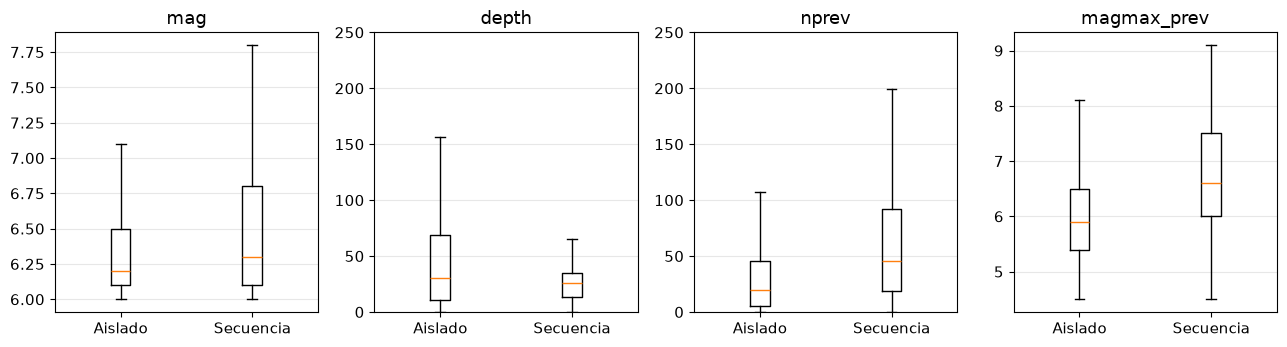

In [4]:
FEATURES = ['mag', 'depth', 'lat', 'lon', 'nprev', 'magmax_prev']

filas = []
for f in FEATURES:
    neg = datos[datos.y == 0][f]
    pos = datos[datos.y == 1][f]
    filas.append({'feature': f,
                  'mediana (aislado)': neg.median(),
                  'mediana (secuencia)': pos.median(),
                  '% de positivos sobre la mediana': 100 * (pos > neg.median()).mean()})

separacion = pd.DataFrame(filas).set_index('feature')
display(separacion.round(1))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, f in zip(axes, ['mag', 'depth', 'nprev', 'magmax_prev']):
    ax.boxplot([datos[datos.y == 0][f], datos[datos.y == 1][f]], showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Aislado', 'Secuencia'])
    ax.set_title(f)
    ax.grid(alpha=0.3, axis='y')
axes[1].set_ylim(0, 250)
axes[2].set_ylim(0, 250)
plt.tight_layout()
plt.show()

Lo que entrega esta primera exploración es que ninguna feature separa bien las clases por sí sola. Las mejores son las dos que construimos nosotros, con un 76 % en "magmax_prev" y un 74 % en "nprev". Las features que vienen del catálogo quedan bastante más atrás, 58 % la magnitud y 43% la profundidad ("depth"). Los box plot muestran lo mismo, en todas las variables las cajas de los dos grupos se superponen.

Que las features construidas sean más informativas que las del catálogo tiene sentido físico, ya que lo que mejor anticipa que vengan más sismos es saber que la zona ya estaba activa previamente.

La información entregada por las features de coordenadas del epicentro, "lat" y "lon" es puramente geográfica, ya que muestra que las zonas del pacífico occidental producen más secuencias. Las dejamos igual porque pueden ayudar al modelo a diferenciar regímenes tectónicos, aunque no digan nada físico sobre el evento en sí.

Con este análisis concluimos que con la señal así de débil y repartida no esperamos un clasificador preciso. Pero esto es justamente lo que puede aportar un árbol de decisión, combinar cortes del tipo "zona activa y además ya hubo un evento grande", condiciones que por separado no alcanzan, por lo cual decidimos usar el arbol de decisión como algoritmo de machine learning para nuestra tarea.

---
## 4. Separación de datos, train y test

Dividimos el dataset por año, entrenamiento de 1980 a 2012 y test de 2013 a 2025. No usamos una división aleatoria y vale la pena explicar por qué.

Las observaciones de este dataset no son independientes entre sí. Los sismos de una misma secuencia ocurren en el mismo lugar con pocos días de diferencia, así que comparten casi los mismos valores de features como latitud, longitud, actividad previa y magnitud máxima previa. Con una división al azar los eventos de una misma secuencia caerían a los dos lados y estaríamos evaluando el modelo con casos prácticamente idénticos a los que ya vio en el entrenamiento. Además, la división temporal reproduce el uso real, ya que en la práctica siempre se predice el futuro con datos del pasado.

El corte en 2012 deja un 73 % de los datos para entrenar y un 27 % para probar, con casi la misma proporción de positivos en los dos conjuntos (23,4 % y 23,2 %).

Entre los algoritmos vistos en clases elegimos árbol de decisión por tres motivos. Primero, no necesita escalar las features, y nuestras variables están en unidades y escalas distintas: magnitudes entre 6 y 9, profundidades entre 0 y 700 km, conteos entre 0 y 1891. Un algoritmo basado en distancias como kNN nos obligaría a normalizar antes. Segundo, es interpretable, podemos mirar el árbol y ver qué condiciones está usando. Y tercero, la profundidad máxima del árbol controla directamente cuánto puede memorizar, así que es un parámetro cómodo para el experimento de la sección 6.

Sobre la configuración, fijamos "max_depth=5" como un valor moderado antes de ver ningún resultado, para no dejar que el árbol crezca sin control. Usamos también "class_weight='balanced" porque con las clases desbalanceadas el árbol tendería a predecir casi siempre la clase mayoritaria, y esta opción hace que los errores sobre la clase minoritaria pesen más durante el entrenamiento. No normalizamos ni imputamos nada, así que no hay transformaciones que puedan filtrar información del test hacia el entrenamiento.

In [5]:
FEATURES = ['mag', 'depth', 'lat', 'lon', 'nprev', 'magmax_prev']
ANIO_CORTE = 2012

train = datos[datos.year <= ANIO_CORTE]
test  = datos[datos.year >  ANIO_CORTE]

X_train, y_train = train[FEATURES], train['y']
X_test,  y_test  = test[FEATURES],  test['y']

print(f"Entrenamiento 1980–{ANIO_CORTE}: {len(train):5d} eventos "
      f"({100*y_train.mean():.1f} % positivos)")
print(f"Test          {ANIO_CORTE+1}–2025: {len(test):5d} eventos "
      f"({100*y_test.mean():.1f} % positivos)")

arbol = DecisionTreeClassifier(max_depth=5,
                               class_weight='balanced',
                               random_state=0)
arbol.fit(X_train, y_train)

print(f"\nÁrbol entrenado: {arbol.get_n_leaves()} hojas")

Entrenamiento 1980–2012:  4877 eventos (23.4 % positivos)
Test          2013–2025:  1773 eventos (23.2 % positivos)

Árbol entrenado: 32 hojas


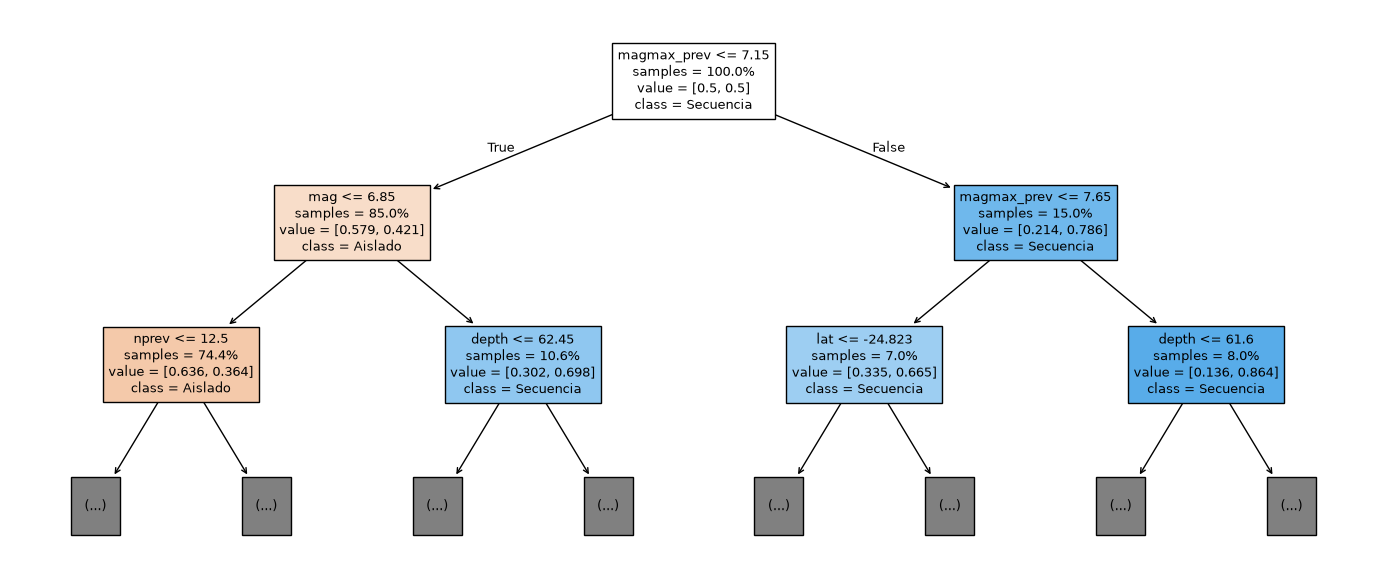

In [6]:
# Primeros dos niveles del árbol, para ver qué aprendió
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arbol, max_depth=2, feature_names=FEATURES,
          class_names=['Aislado', 'Secuencia'],
          filled=True, impurity=False, proportion=True, fontsize=9, ax=ax)
plt.tight_layout()
plt.show()

El primer corte del árbol es "magmax_prev <= 7.15", o sea que lo primero que mira el modelo es si en el año anterior ya hubo un sismo menor o igual a esa magnitud cerca. Ese 15 % de casos que supera el umbral tiene un 78,6 % de probabilidad de ser secuencia, contra el 42 % del resto.

Hacia el lado izquierdo, donde no hubo un evento previo tan grande, el árbol recurre a la magnitud del propio sismo y después a la cantidad de eventos previos. Básicamente reconstruye por su cuenta que una secuencia es más probable si la zona ya estaba activa, si el evento es grande, o las dos cosas.

---
## 5. Evaluación del desempeño

Lo primero es descartar el accuracy como métrica. Con un ~77 % de casos negativos, un modelo que respondiera siempre "no habrá secuencia" sacaría ~77 % de exactitud sin haber aprendido nada y además no nos entregaría info, porque no detectaría ninguna secuencia sismica.

Usamos entonces estas tres métricas:

- Recall: de todas las secuencias que realmente ocurrieron, qué fracción detectó el modelo. Es TP / (TP + FN).
- Precision: de todas las veces que el modelo clasificó una secuencia sísmica, cuántas eran de verdad una secuencia. Es TP / (TP + FP).
- F1: El equilibrio entre las dos anteriores, la tomamos como métrica principal porque ninguna de las dos sirve sola, se puede tener recall perfecto pero con poca pureza o precisión alta perdiendo completitud.

Mostramos también la matriz de confusión completa, que deja ver exactamente como se van clasificando los distintos sismos.

Para este problema el recall nos importa más que la precisión. Si el modelo avisa de una secuencia que no ocurre, el costo es una alerta de más. Si no avisa de una que sí ocurre, el costo es bastante mayor.

In [7]:
for nombre, X, y_real in [('ENTRENAMIENTO', X_train, y_train), ('TEST', X_test, y_test)]:
    y_pred = arbol.predict(X)

    print(f"===== {nombre} =====")
    cm = confusion_matrix(y_real, y_pred)
    print(pd.DataFrame(cm,
                       index=['Real: aislado', 'Real: secuencia'],
                       columns=['Pred: aislado', 'Pred: secuencia']))
    print()
    print(classification_report(y_real, y_pred,
                                target_names=['Aislado', 'Secuencia'], digits=3))

# Referencia: clasificador trivial que siempre responde "aislado"
print(f"Exactitud de un clasificador trivial en test: {1 - y_test.mean():.3f}")

===== ENTRENAMIENTO =====
                 Pred: aislado  Pred: secuencia
Real: aislado             2955              779
Real: secuencia            416              727

              precision    recall  f1-score   support

     Aislado      0.877     0.791     0.832      3734
   Secuencia      0.483     0.636     0.549      1143

    accuracy                          0.755      4877
   macro avg      0.680     0.714     0.690      4877
weighted avg      0.784     0.755     0.766      4877

===== TEST =====
                 Pred: aislado  Pred: secuencia
Real: aislado             1060              302
Real: secuencia            157              254

              precision    recall  f1-score   support

     Aislado      0.871     0.778     0.822      1362
   Secuencia      0.457     0.618     0.525       411

    accuracy                          0.741      1773
   macro avg      0.664     0.698     0.674      1773
weighted avg      0.775     0.741     0.753      1773

Exactitud de 

El modelo aprendió algo real. En test detecta el 62 % de las secuencias con un F1 de 0,525 sobre la clase positiva. De los 411 eventos que sí abrieron secuencia identificó 254 y se le escaparon 157, y a cambio lanzó 302 alertas falsas, así que menos de la mitad de sus avisos son correctos, hay mala.

Sobre el sobreajuste, la diferencia entre entrenamiento y test es chica en todas las métricas, el recall baja de 0,636 a 0,618 y el F1 de 0,549 a 0,525. El modelo rinde en datos nuevos casi igual que en los que usó para aprender.

---
## 6. Experimento con el modelo

Lo que modificamos es "max_depth", la profundidad máxima que puede alcanzar el árbol, todo lo demás queda igual.

Antes de correrlo, lo que esperamos según lo visto en clases sobre sesgo y varianza es lo siguiente:

En entrenamiento el F1 debería crecer a medida que aumentamos la profundidad. Cada nivel adicional permite hacer más cortes y aislar grupos cada vez más chicos y más especificos, y sin límite el árbol puede seguir dividiendo hasta dejar hojas con un solo dato clasificado, o sea memorizar los datos de entrenamiento y llegar a un F1 cercano a 1.

En test esperamos una curva con un máximo en donde la profundida sea "ideal" pero a medida que aumentamos la profundidad, en cierto punto, se va a empezar a ajustar el ruido de los datos de entrenamiento que no se repiten en los datos de test y el desempeño decaerá. 

Con esto también esperamos que la brecha entre las dos curvas crezca mientras más profundo sea el árbol.

In [8]:
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]

resultados = []
for p in profundidades:
    m = DecisionTreeClassifier(max_depth=p, class_weight='balanced', random_state=0)
    m.fit(X_train, y_train)
    resultados.append({
        'max_depth': 'sin límite' if p is None else p,
        'hojas':     m.get_n_leaves(),
        'F1 train':  f1_score(y_train, m.predict(X_train)),
        'F1 test':   f1_score(y_test,  m.predict(X_test))})

exp = pd.DataFrame(resultados).set_index('max_depth')
display(exp.round(3))

,hojas,F1 train,F1 test
max_depth,,,
1,2,0.414,0.426
2,4,0.503,0.486
3,8,0.517,0.487
4,16,0.501,0.471
5,32,0.549,0.525
6,55,0.569,0.501
8,140,0.622,0.483
10,290,0.671,0.444
15,714,0.863,0.343


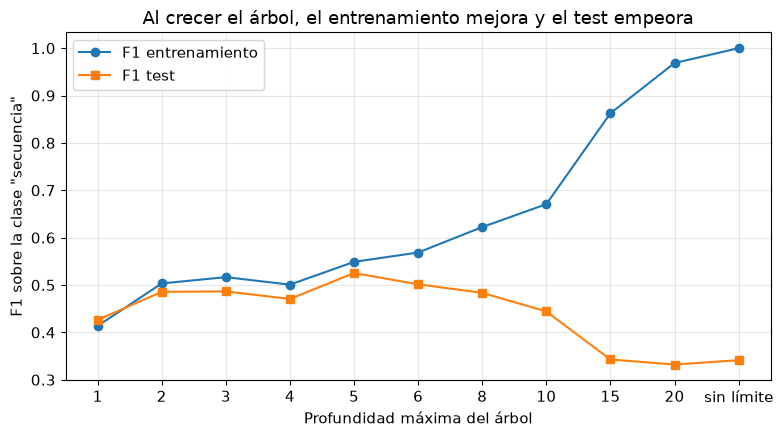

In [9]:
x = range(len(profundidades))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, exp['F1 train'], 'o-', label='F1 entrenamiento')
ax.plot(x, exp['F1 test'],  's-', label='F1 test')
ax.set_xticks(list(x))
ax.set_xticklabels(exp.index)
ax.set_xlabel('Profundidad máxima del árbol')
ax.set_ylabel('F1 sobre la clase "secuencia"')
ax.set_title('Al crecer el árbol, el entrenamiento mejora y el test empeora')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Tal como se dijo en la predicción. El F1 de entrenamiento crece de 0,414 hasta 1,000, o sea que el árbol sin restricción termina clasificando perfectamente los datos que ya conoce. El de test en cambio sube hasta un máximo de 0,525 en "max_depth=5" y después cae hasta 0,325.

El árbol sin límite es el caso extremo. Saca un F1 perfecto en entrenamiento y queda en 0,351 en test, peor todavía que el árbol de un solo corte. Memorizó en vez de aprender.

La brecha entre las dos curvas es lo que mide el sobreajuste. Con "max_depth=1" están prácticamente pegadas, con "max_depth=5" la diferencia es de 0,024 y con "max_depth=20" llega a 0,644.

Lo que nos deja el experimento es que la capacidad del modelo no es el factor limitante. Pasar de 32 a 979 hojas no mejora nada, lo empeora. Ya que hay un sobreajuste importante.

---
## 7. Auditoría del modelo

Las métricas que se han usado hasta ahora son promedios sobre todo el conjunto de test y no dicen dónde el modelo funciona y dónde no. Ahora lo revisamos:

In [14]:
err = test.copy()
err['prob'] = arbol.predict_proba(X_test)[:, 1]
err['pred'] = arbol.predict(X_test)

def clasificar_error(fila):
    if fila.y == 1 and fila.pred == 1: return 'TP (secuencia detectada)'
    if fila.y == 1 and fila.pred == 0: return 'FN (secuencia no detectada)'
    if fila.y == 0 and fila.pred == 1: return 'FP (alerta falsa)'
    return 'TN (aislado, bien)'

err['tipo'] = err.apply(clasificar_error, axis=1)

print(err['tipo'].value_counts().to_string())
print("\nValor mediano de cada feature según el tipo de resultado:")
display(err.groupby('tipo')[['mag', 'depth', 'nprev', 'magmax_prev']].median().round(1))

tipo
TN (aislado, bien)             1060
FP (alerta falsa)               302
TP (secuencia detectada)        254
FN (secuencia no detectada)     157

Valor mediano de cada feature según el tipo de resultado:


,mag,depth,nprev,magmax_prev
tipo,,,,
FN (secuencia no detectada),6.2,18.0,34.0,6.2
FP (alerta falsa),6.3,20.6,54.0,6.4
"TN (aislado, bien)",6.2,21.9,18.0,5.7
TP (secuencia detectada),6.4,19.4,88.5,7.1


In [11]:
# ¿El desempeño es parejo en todo tipo de sismo?
err['rango_prof'] = pd.cut(err.depth, [-5, 70, 300, 800],
                           labels=['Superficial (<70 km)', 'Intermedio (70–300)', 'Profundo (>300)'])
err['rango_mag']  = pd.cut(err.mag, [5.9, 6.25, 6.5, 7.0, 10],
                           labels=['6,0–6,25', '6,25–6,5', '6,5–7,0', '> 7,0'])

for col in ['rango_prof', 'rango_mag']:
    filas = []
    for g, sub in err.groupby(col, observed=True):
        pos = sub[sub.y == 1]
        filas.append({col: g, 'n': len(sub),
                      'secuencias reales': len(pos),
                      'recall': pos.pred.mean() if len(pos) else np.nan})
    display(pd.DataFrame(filas).set_index(col).round(3))

,n,secuencias reales,recall
rango_prof,,,
Superficial (<70 km),1368,369,0.664
Intermedio (70–300),256,24,0.083
Profundo (>300),149,18,0.389


,n,secuencias reales,recall
rango_mag,,,
"6,0–6,25",890,182,0.538
"6,25–6,5",416,79,0.544
"6,5–7,0",323,87,0.678
"> 7,0",144,63,0.857


In [12]:
print("Los cinco sismos más grandes cuya secuencia NO fue detectada:\n")
print(err[(err.y == 1) & (err.pred == 0)].nlargest(5, 'mag')[
    ['fecha', 'mag', 'depth', 'nprev', 'magmax_prev', 'prob', 'place']].to_string(index=False))

print("\n\nLas cuatro alertas falsas más confiadas:\n")
print(err[(err.y == 0) & (err.pred == 1)].nlargest(4, 'prob')[
    ['fecha', 'mag', 'depth', 'nprev', 'magmax_prev', 'prob', 'place']].to_string(index=False))

Los cinco sismos más grandes cuya secuencia NO fue detectada:

     fecha  mag  depth  nprev  magmax_prev     prob                                       place
2025-07-29  8.8  35.00  212.0          7.4 0.000000 2025 Kamchatka Peninsula, Russia Earthquake
2018-08-19  8.2 600.00   70.0          6.4 0.473235                        2018 Fiji Earthquake
2021-07-29  8.2  35.00   64.0          7.6 0.000000             2021 Chignik, Alaska Earthquake
2021-08-12  8.1  22.79   54.0          7.5 0.000000      2021 South Sandwich Islands Earthquake
2014-06-23  7.9 109.00   18.0          5.2 0.258415       Rat Islands, Aleutian Islands, Alaska


Las cuatro alertas falsas más confiadas:

     fecha  mag  depth  nprev  magmax_prev     prob                                         place
2015-09-26  6.3   46.0  287.0          8.3 0.950536                    26 km SSW of Ovalle, Chile
2016-02-22  6.0   12.0  403.0          8.3 0.950536                 105 km WSW of Coquimbo, Chile
2025-11-04  6.0   28.0 

In [13]:
# ¿Por qué el modelo le dio probabilidad cero al M 8,8 de Kamchatka?
kam = err[err.place.str.contains('Kamchatka Peninsula')].iloc[0]
camino = arbol.decision_path(kam[FEATURES].values.reshape(1, -1)).indices
t_ = arbol.tree_

print("Camino que siguió ese evento dentro del árbol:")
for n in camino:
    if t_.feature[n] >= 0:
        f = FEATURES[t_.feature[n]]
        print(f"   {f} = {kam[f]:.2f}  "
              f"{'<=' if kam[f] <= t_.threshold[n] else '>'} {t_.threshold[n]:.2f}")
    else:
        print(f"   HOJA FINAL: solo {int(t_.n_node_samples[n])} caso(s) de entrenamiento")

Camino que siguió ese evento dentro del árbol:
   magmax_prev = 7.40  > 7.15
   magmax_prev = 7.40  <= 7.65
   lat = 52.49  > -24.82
   mag = 8.80  > 7.05
   lat = 52.49  > 39.53
   HOJA FINAL: solo 1 caso(s) de entrenamiento


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


### 1. ¿Qué tan bien generaliza el modelo?

De manera global generaliza bien. El F1 baja de 0,549 en entrenamiento a 0,525 en test y el recall de 0,636 a 0,618, son caidas chicas lo que nos ayuda a descartar un sobreajuste importante. Tampoco se ve un subajuste, porque el experimento de la sección anterior nos mostró que con profundidad 1 el F1 de test caía a 0,426, así que el modelo sí está aprovechando su capacidad.

Ahora donde se ven problemas en cuando vemos ciertos datos especificos. Al seguir el camino del sismo M 8,8 de Kamchatka de 2025 se puede ver que terminó en una hoja construida con un solo caso de entrenamiento y que además era de clase negativa. Por eso el modelo le dió 0 de probabilidad de generar réplicas a uno de los eventos más grandes del catálogo y que obviamente las tuvo.

O sea que "max_depth=5" controla el sobreajuste global, pero eso no quiere decir que algunas hojas queden armadas con muy pocos datos de entrenamiento. En esas ramas el modelo no generaliza nada y repite lo que aprendió de unos casos muy especificos.

### 2. ¿Dónde falla el modelo?

Donde más falla es en los sismos de profundidad intermedia como ver acá:

| Rango | Secuencias reales | Recall |
|---|---|---|
| Superficial (< 70 km) | 369 | 0,664 |
| Intermedio (70–300 km) | 24 | 0,083 |
| Profundo (> 300 km) | 18 | 0,389 |

En esa profundidad solo puede detectar el 8% de las 24 secuencias reales que habían. El modelo aprendió que los sismos profundos rara vez generan secuencias, lo cual en general es correcto, pero lo aplica de una forma que pierde casi todos los casos que sí ocurren ahí.

También falla más en los sismos chicos, que son la mayoría. El recall va de 0,538 entre M 6,0 y 6,25 hasta 0,857 sobre M 7. El tema es que el grupo de magnitud mas pequeña tiene 890 eventos y el de magnitudes grandes apenas 144, así que la mayor parte de los errores se concentra donde el modelo es más débil.

Al mirar las medianas, las secuencias que el modelo no detectó (FN) tenían "nprev = 34" y "magmax_prev = 6,2", mientras que las que sí detectó (TN) tenían 88,5 y 7,1. Y las alertas falsas (FP) tenían "nprev" = 54" contra 18 de los aislados bien clasificados (TN). Aqui se puede ver una clara tendencia en la clasificación

El modelo acierta cuando la zona ya venía activa y se equivoca cuando no. Se le escapan justamente las secuencias que empiezan de cero, que son las más sorpresivas y las que más valdría la pena anticipar, y lanza alertas falsas en zonas que llevan meses temblando.

### 3. ¿Qué aprendimos que no era evidente desde una única métrica global?

Lo del accuracy que vimos en la sección 5 es el caso más claro. Esa métrica sola nos habría llevado a la conclusión contraria, que el modelo es peor que no hacer nada.

Después está el tema de los subgrupos. El recall de 0,618 es una metrica que mezcla el 0,664 en sismos superficiales con 0,083 en los intermedios. Si alguien usara este modelo en una zona de subducción profunda estaría usando algo que ahí no funciona, y esto no se podía ver solo con ese 0,618.

Y lo último, que para nosotros es lo más importante: mirando qué variables usa y en qué casos se acierta, queda claro que el modelo está reconociendo si ya estamos dentro de una secuencia activa más que anticipando el inicio de una nueva.

### 4. ¿Cómo mejorarían el modelo?

La mejora más directa sería exigir un mínimo de observaciones por hoja con el parámetro "min_samples_leaf". El caso de Kamchatka mostró que hay hojas armadas con un solo ejemplo y ahí el modelo no generaliza bien. Poniendo un mínimo de unas 50 observaciones por ejemplo, ningún caso nuevo recibiría una predicción basada en una coincidencia aislada y las probabilidades serían más confiables. No esperaríamos que cambie mucho el desempeño global, pero sí que desaparezcan los errores extremos como ese M 8,8 en una hoja sola.

Otra mejora sería agregar features que describan la tendencia reciente y no solo el nivel acumulado, por ejemplo cuántos sismos hubieron en los últimos 30 días comparados con el promedio del año. Nuestras features actuales dicen si la zona es activa, pero no si se está activando ahora, que podría ser lo que distingue a una secuencia que está por nacer.

---
## Uso de herramientas de inteligencia artificial

Usamos Claude (Anthropic) como apoyo para programar y depurar el código, verificar que las cifras del texto coincidieran con las salidas del notebook, y redactar parte de las celdas de interpretación.

La definición del problema, las decisiones metodológicas (como el corte temporal del split, la elección del algoritmo, el aspecto a variar en el experimento) y la interpretación de los resultados fueron discutidas y elegidas por los integrantes del grupo.